# Dissecting wav2vec2

[wav2vec2](https://arxiv.org/abs/2006.11477) (Baevski et al. 2020) is the frozen backbone of assignment 3.
This notebook takes the pre-trained `facebook/wav2vec2-base` from the `transformers` library apart with PyTorch
introspection — printing modules, counting parameters, and recording the shape of every tensor that flows through it —
and plots what the main blocks do with a real recording.

The point: the whole model is built from a handful of basic blocks you already know —
**1D convolutions, normalization layers (group norm and layer norm), GELU activations, dense (linear) layers,
and multi-head self-attention**.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
import torch
from transformers import Wav2Vec2Model
from transformers.utils import logging as transformers_logging

# Hide the report of the pre-training weights that are not used here (wav2vec2's quantizer).
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
torch.manual_seed(0)
%config InlineBackend.figure_format = 'retina'

model = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base").eval()
config = model.config

# one color per kind of basic block, used in all plots below
COLORS = {"conv": "#2a78d6", "norm": "#eb6834", "attention": "#1baf7a", "dense": "#eda100", "activation": "#e87ba4"}

## 1. The module tree

`print(model)` shows the nested `torch.nn.Module`s. PyTorch already collapses identical repeated layers
(e.g. `(0-11): 12 x Wav2Vec2EncoderLayer`). `Dropout` layers do nothing in `eval()` mode — they only matter in training.

In [2]:
print(model)

Wav2Vec2Model(
  (feature_extractor): Wav2Vec2FeatureEncoder(
    (conv_layers): ModuleList(
      (0): Wav2Vec2GroupNormConvLayer(
        (conv): Conv1d(1, 512, kernel_size=(10,), stride=(5,), bias=False)
        (activation): GELUActivation()
        (layer_norm): GroupNorm(512, 512, eps=1e-05, affine=True, bias=True)
      )
      (1-4): 4 x Wav2Vec2NoLayerNormConvLayer(
        (conv): Conv1d(512, 512, kernel_size=(3,), stride=(2,), bias=False)
        (activation): GELUActivation()
      )
      (5-6): 2 x Wav2Vec2NoLayerNormConvLayer(
        (conv): Conv1d(512, 512, kernel_size=(2,), stride=(2,), bias=False)
        (activation): GELUActivation()
      )
    )
  )
  (feature_projection): Wav2Vec2FeatureProjection(
    (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
    (projection): Linear(in_features=512, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): Wav2Vec2Encoder(
    (pos_conv_embed): Wav2Vec2Posit

The model has three top-level stages:

1. `feature_extractor` — a stack of 7 convolutions that turns the raw waveform into one 512-d vector every 20 ms (a *frame*);
2. `feature_projection` — a layer norm and a dense layer that map each frame to 768 dimensions;
3. `encoder` — a convolutional positional embedding followed by 12 Transformer layers.

The configuration values that determine the architecture:

In [3]:
{k: getattr(config, k) for k in [
    "conv_dim", "conv_kernel", "conv_stride", "conv_bias", "feat_extract_norm", "feat_extract_activation",
    "hidden_size", "num_hidden_layers", "num_attention_heads", "intermediate_size", "hidden_act",
    "num_conv_pos_embeddings", "num_conv_pos_embedding_groups", "do_stable_layer_norm", "layer_norm_eps",
]}

{'conv_dim': [512, 512, 512, 512, 512, 512, 512],
 'conv_kernel': [10, 3, 3, 3, 3, 2, 2],
 'conv_stride': [5, 2, 2, 2, 2, 2, 2],
 'conv_bias': False,
 'feat_extract_norm': 'group',
 'feat_extract_activation': 'gelu',
 'hidden_size': 768,
 'num_hidden_layers': 12,
 'num_attention_heads': 12,
 'intermediate_size': 3072,
 'hidden_act': 'gelu',
 'num_conv_pos_embeddings': 128,
 'num_conv_pos_embedding_groups': 16,
 'do_stable_layer_norm': False,
 'layer_norm_eps': 1e-05}

### Where the parameters are

In [4]:
def n_params(module: torch.nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())

stages = {
    "feature_extractor": model.feature_extractor,
    "feature_projection": model.feature_projection,
    "encoder.pos_conv_embed": model.encoder.pos_conv_embed,
    "encoder.layer_norm": model.encoder.layer_norm,
    "encoder.layers (12x)": model.encoder.layers,
}
table = pd.DataFrame({"parameters": {name: n_params(m) for name, m in stages.items()}})
table.loc["masked_spec_embed"] = model.masked_spec_embed.numel()  # learned vector that replaces masked frames in pre-training
table.loc["total"] = n_params(model)
table["share"] = (table["parameters"] / n_params(model)).map("{:.1%}".format)
table

,parameters,share
feature_extractor,4200448,4.5%
feature_projection,395008,0.4%
encoder.pos_conv_embed,4719488,5.0%
encoder.layer_norm,1536,0.0%
encoder.layers (12x),85054464,90.1%
masked_spec_embed,768,0.0%
total,94371712,100.0%


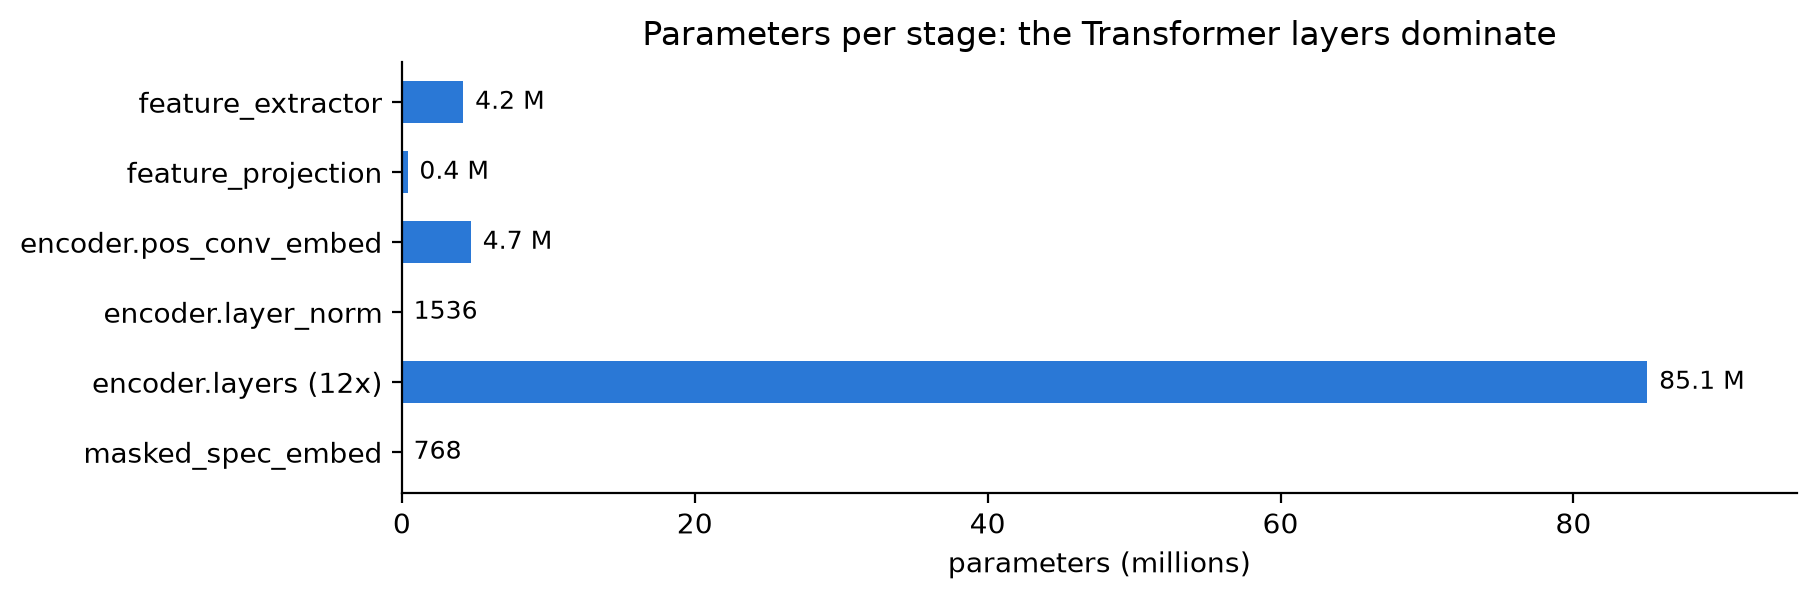

In [5]:
parts = table.drop(index="total")["parameters"][::-1] / 1e6
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(parts.index, parts.values, color=COLORS["conv"], height=0.6)
for y, v in enumerate(parts.values):
    ax.text(v + 0.8, y, f"{v:.1f} M" if v >= 0.1 else f"{v * 1e6:.0f}", va="center", fontsize=9)
ax.set(xlabel="parameters (millions)", title="Parameters per stage: the Transformer layers dominate", xlim=(0, parts.max() * 1.12))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

And grouped by the type of basic block (summed over all occurrences):

In [6]:
by_type = {}
for name, module in model.named_modules():
    own = sum(p.numel() for p in module.parameters(recurse=False))
    if hasattr(module, "parametrizations"):  # weight-normed conv: weights live in a submodule
        own += sum(p.numel() for p in module.parametrizations.parameters())
    if own and "parametrizations" not in name:
        kind = type(module).__name__.replace("Parametrized", "")
        count, total = by_type.get(kind, (0, 0))
        by_type[kind] = (count + 1, total + own)

pd.DataFrame(by_type, index=["modules", "parameters"]).T.sort_values("parameters", ascending=False)

,modules,parameters
Linear,73,85411584
Conv1d,8,8918912
LayerNorm,26,39424
GroupNorm,1,1024
Wav2Vec2Model,1,768


About 90 % of the 94 M parameters are in `Linear` layers (attention projections and feed-forward networks of the
Transformer), most of the rest in `Conv1d`. Normalization layers hold only a few thousand parameters ($\gamma$ and $\beta$).
(The `Wav2Vec2Model` row is `masked_spec_embed`, a parameter of the model itself.)

## 2. Tracing shapes with forward hooks

A *forward hook* is a function PyTorch calls after a module's `forward`, with its inputs and outputs. We register one
on every basic block, run a recording through the model, and record the shapes.

The recording is the same one as in the Spectrogram notebook: a 7.6 s clip from the assignment 3 validation set
(16 kHz, with speech, music, and background sounds). wav2vec2 expects each recording normalized to zero mean and unit variance.

In [7]:
SAMPLE_RATE = 16_000
DATA = "danylo-ucla/speech-fraction/v1"
fs = s3fs.S3FileSystem()


def load_recording(segment, index):
    # The real length of each recording (before the zero padding) is in <segment>_y.parquet.
    samples = pd.read_parquet(f"s3://{DATA}/{segment}_y.parquet").samples[index]
    with fs.open(f"{DATA}/{segment}_x.npy", "rb", block_size=2**20) as f:
        np.lib.format.read_magic(f)
        (_, length), _, dtype = np.lib.format.read_array_header_1_0(f)
        row_bytes = length * dtype.itemsize
        f.seek(f.tell() + index * row_bytes)  # skip the header and the rows before this one
        row = np.frombuffer(f.read(row_bytes), dtype=dtype)
    return row[:samples] / 32768  # int16 -> float in [-1, 1]


audio = load_recording("validate", 4)
wave = torch.tensor((audio - audio.mean()) / audio.std(), dtype=torch.float32)[None]  # (batch, samples)
print(f"{wave.shape[-1]} samples = {wave.shape[-1] / SAMPLE_RATE:.2f} s")

121349 samples = 7.58 s


In [8]:

BASIC = (torch.nn.Conv1d, torch.nn.GroupNorm, torch.nn.LayerNorm, torch.nn.Linear)


def is_traced(name: str, module: torch.nn.Module) -> bool:
    kind = type(module).__name__
    return isinstance(module, BASIC) or kind in ("GELUActivation", "Wav2Vec2SamePadLayer", "Wav2Vec2Attention")


def first_tensor(x):
    while isinstance(x, (tuple, list)):
        x = x[0]
    return x


records = []


def make_hook(name):
    def hook(module, inputs, output):
        records.append({
            "module": name,
            "type": type(module).__name__.replace("Parametrized", ""),
            "input": tuple(first_tensor(inputs).shape),
            "output": tuple(first_tensor(output).shape),
            "parameters": 0 if type(module).__name__ == "Wav2Vec2Attention" else n_params(module),
        })
    return hook


handles = [m.register_forward_hook(make_hook(n)) for n, m in model.named_modules() if is_traced(n, m)]
with torch.no_grad():
    out = model(wave, output_hidden_states=True)
for h in handles:
    h.remove()

trace = pd.DataFrame(records)
len(trace)

141

The 12 Transformer layers are identical: check that each one produces exactly the same sequence of shapes,
then show only one of them (labelled `layers.*`).

In [9]:
trace["layer"] = trace["module"].str.extract(r"encoder\.layers\.(\d+)\.")[0]
per_layer = [g[["type", "input", "output", "parameters"]].reset_index(drop=True)
             for _, g in trace.dropna(subset="layer").groupby("layer")]
assert len(per_layer) == config.num_hidden_layers and all(p.equals(per_layer[0]) for p in per_layer)

collapsed = trace[trace["layer"].isna() | (trace["layer"] == "0")].drop(columns="layer")
collapsed["module"] = collapsed["module"].str.replace("encoder.layers.0.", "encoder.layers.*.")

with pd.option_context("display.max_rows", 100, "display.max_colwidth", 60):
    display(collapsed.reset_index(drop=True))

,module,type,input,output,parameters
0,feature_extractor.conv_layers.0.conv,Conv1d,"(1, 1, 121349)","(1, 512, 24268)",5120
1,feature_extractor.conv_layers.0.layer_norm,GroupNorm,"(1, 512, 24268)","(1, 512, 24268)",1024
2,feature_extractor.conv_layers.0.activation,GELUActivation,"(1, 512, 24268)","(1, 512, 24268)",0
3,feature_extractor.conv_layers.1.conv,Conv1d,"(1, 512, 24268)","(1, 512, 12133)",786432
4,feature_extractor.conv_layers.1.activation,GELUActivation,"(1, 512, 12133)","(1, 512, 12133)",0
5,feature_extractor.conv_layers.2.conv,Conv1d,"(1, 512, 12133)","(1, 512, 6066)",786432
6,feature_extractor.conv_layers.2.activation,GELUActivation,"(1, 512, 6066)","(1, 512, 6066)",0
7,feature_extractor.conv_layers.3.conv,Conv1d,"(1, 512, 6066)","(1, 512, 3032)",786432
8,feature_extractor.conv_layers.3.activation,GELUActivation,"(1, 512, 3032)","(1, 512, 3032)",0
9,feature_extractor.conv_layers.4.conv,Conv1d,"(1, 512, 3032)","(1, 512, 1515)",786432


### The architecture as a diagram

The same information as a picture: one box per basic block, colored by kind, with the output shape of each block
read from the trace above ($B$ = batch, $T$ = frames). Repeated convolutions are merged into one box, and the 12
Transformer layers into one bracket. The arrows on the left are residual connections: the input of a sub-layer is
added to its output.

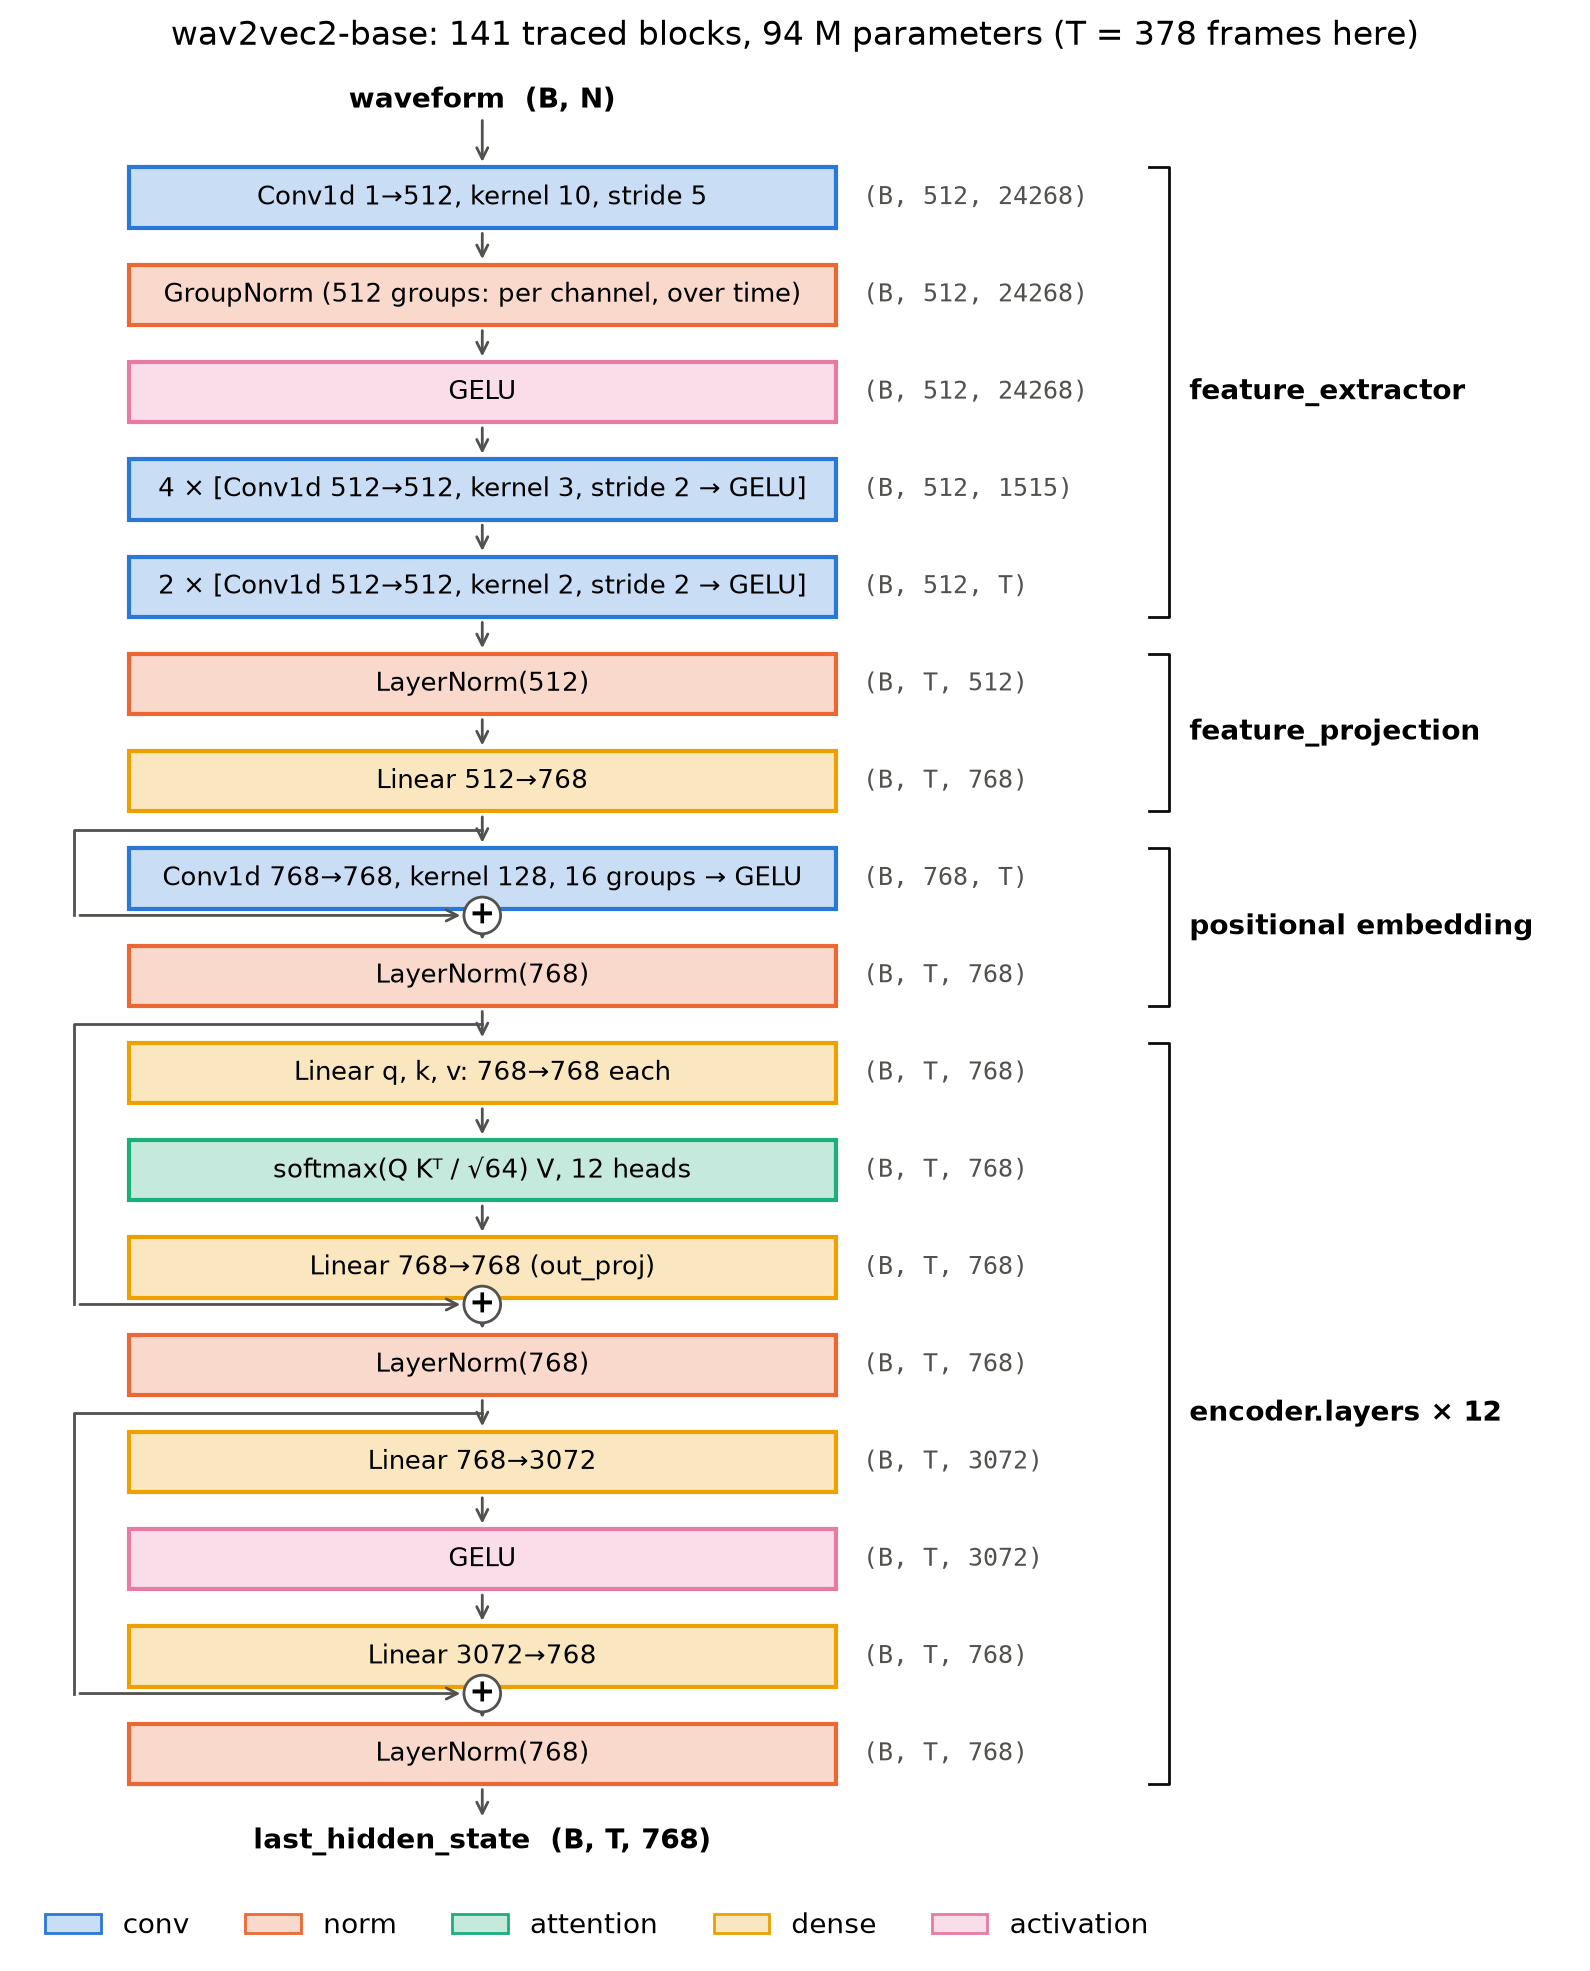

In [10]:
out_shape = dict(zip(collapsed["module"], collapsed["output"]))
T = out_shape["encoder.layer_norm"][1]


def shape(name):
    dims = ["B"] + ["T" if n == T else str(n) for n in out_shape[name][1:]]
    return "(" + ", ".join(dims) + ")"


fe, enc, layer = "feature_extractor.conv_layers", "encoder", "encoder.layers.*"
blocks = [  # (label, kind, module whose output shape is shown)
    ("Conv1d 1→512, kernel 10, stride 5", "conv", f"{fe}.0.conv"),
    ("GroupNorm (512 groups: per channel, over time)", "norm", f"{fe}.0.layer_norm"),
    ("GELU", "activation", f"{fe}.0.activation"),
    ("4 × [Conv1d 512→512, kernel 3, stride 2 → GELU]", "conv", f"{fe}.4.activation"),
    ("2 × [Conv1d 512→512, kernel 2, stride 2 → GELU]", "conv", f"{fe}.6.activation"),
    ("LayerNorm(512)", "norm", "feature_projection.layer_norm"),
    ("Linear 512→768", "dense", "feature_projection.projection"),
    ("Conv1d 768→768, kernel 128, 16 groups → GELU", "conv", f"{enc}.pos_conv_embed.activation"),
    ("LayerNorm(768)", "norm", f"{enc}.layer_norm"),
    ("Linear q, k, v: 768→768 each", "dense", f"{layer}.attention.q_proj"),
    ("softmax(Q Kᵀ / √64) V, 12 heads", "attention", f"{layer}.attention.out_proj"),
    ("Linear 768→768 (out_proj)", "dense", f"{layer}.attention.out_proj"),
    ("LayerNorm(768)", "norm", f"{layer}.layer_norm"),
    ("Linear 768→3072", "dense", f"{layer}.feed_forward.intermediate_dense"),
    ("GELU", "activation", f"{layer}.feed_forward.intermediate_act_fn"),
    ("Linear 3072→768", "dense", f"{layer}.feed_forward.output_dense"),
    ("LayerNorm(768)", "norm", f"{layer}.final_layer_norm"),
]
groups = [(0, 4, "feature_extractor"), (5, 6, "feature_projection"), (7, 8, "positional embedding"),
          (9, 16, "encoder.layers × 12")]
residuals = [(7, 7), (9, 11), (13, 15)]  # (first, last) block inside each skip; summed before the next block

step, box_h = 1.0, 0.62
fig, ax = plt.subplots(figsize=(10, 12))
y = lambda i: -(i + 1) * step
ax.text(0, 0, "waveform  (B, N)", ha="center", va="center", fontsize=10, weight="bold")
for i, (label, kind, module) in enumerate(blocks):
    ax.add_patch(plt.Rectangle((-2.6, y(i) - box_h / 2), 5.2, box_h, facecolor=COLORS[kind] + "40",
                               edgecolor=COLORS[kind], lw=1.5))
    ax.text(0, y(i), label, ha="center", va="center", fontsize=9.5)
    ax.text(2.8, y(i), shape(module), ha="left", va="center", fontsize=9, color="#52514e", family="monospace")
    ax.annotate("", (0, y(i) + box_h / 2), (0, y(i - 1) + (box_h / 2 if i else 0) * -1 + (0 if i else -0.15)),
                arrowprops=dict(arrowstyle="->", color="#52514e", lw=1))
for first, last in residuals:  # skip arrow from above `first` to below `last`
    top, bottom = y(first) + step / 2, y(last) - step / 2 + 0.12
    ax.plot([0, -3.0, -3.0], [top, top, bottom], color="#52514e", lw=1)
    ax.annotate("", (-0.12, bottom), (-3.0, bottom), arrowprops=dict(arrowstyle="->", color="#52514e", lw=1))
    ax.text(0, bottom, "+", ha="center", va="center", fontsize=11, weight="bold",
            bbox=dict(boxstyle="circle,pad=0.1", fc="white", ec="#52514e"))
for first, last, name in groups:
    top, bottom = y(first) + box_h / 2, y(last) - box_h / 2
    ax.plot([4.9, 5.05, 5.05, 4.9], [top, top, bottom, bottom], color="#0b0b0b", lw=1)
    ax.text(5.2, (top + bottom) / 2, name, va="center", fontsize=10, weight="bold")
ax.text(0, y(len(blocks)) + 0.1, "last_hidden_state  (B, T, 768)", ha="center", va="center", fontsize=10, weight="bold")
ax.annotate("", (0, y(len(blocks)) + 0.3), (0, y(len(blocks) - 1) - box_h / 2), arrowprops=dict(arrowstyle="->", color="#52514e"))
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c + "40", edgecolor=c) for c in COLORS.values()]
ax.legend(handles, COLORS.keys(), loc="lower left", ncols=5, frameon=False, bbox_to_anchor=(0.0, -0.03))
ax.set(xlim=(-3.4, 8), ylim=(y(len(blocks)) - 0.6, 0.4))
ax.axis("off")
ax.set_title(f"wav2vec2-base: {len(trace)} traced blocks, {n_params(model) / 1e6:.0f} M parameters (T = {T} frames here)")
plt.show()

Reading the table top to bottom is reading the forward pass. Note the axis convention changes:
convolutions work on `(batch, channels, time)`, while the projection and the Transformer work on `(batch, time, features)`.

The hook order also reveals the connections inside a Transformer layer: `attention` (which internally calls
`q_proj`, `k_proj`, `v_proj`, then `out_proj` — so they are recorded first), then `layer_norm`, the feed-forward
network (`intermediate_dense` → GELU → `output_dense`), then `final_layer_norm`. The residual additions are not modules,
so the hooks can't see them; the diagram above shows them as arrows.

## 3. The feature encoder: waveform → frames

Seven `Conv1d` layers without padding. A convolution with kernel size $k$ and stride $s$ turns $L$ time steps into

$$L_\text{out} = \left\lfloor \frac{L - k}{s} \right\rfloor + 1$$

In [11]:
rows, length, receptive, jump = [], wave.shape[-1], 1, 1
for i, layer in enumerate(model.feature_extractor.conv_layers):
    conv = layer.conv
    (k,), (s,) = conv.kernel_size, conv.stride
    length = (length - k) // s + 1
    receptive += (k - 1) * jump  # how many input samples one output step sees
    jump *= s                    # how many input samples between consecutive output steps
    rows.append({"layer": i, "in_channels": conv.in_channels, "out_channels": conv.out_channels, "kernel": k, "stride": s,
                 "norm": type(getattr(layer, "layer_norm", None)).__name__.replace("NoneType", "-"),
                 "output length": length, "receptive field (samples)": receptive, "hop (samples)": jump})
pd.DataFrame(rows).set_index("layer")

,in_channels,out_channels,kernel,stride,norm,output length,receptive field (samples),hop (samples)
layer,,,,,,,,
0,1,512,10,5,GroupNorm,24268,10,5
1,512,512,3,2,-,12133,20,10
2,512,512,3,2,-,6066,40,20
3,512,512,3,2,-,3032,80,40
4,512,512,3,2,-,1515,160,80
5,512,512,2,2,-,757,240,160
6,512,512,2,2,-,378,400,320


- The total stride is $5 \cdot 2^6 = 320$ samples = **20 ms** at 16 kHz: one second of audio becomes 49 frames.
- Each frame sees a window of **400 samples = 25 ms** of audio — the same window size as a classic spectrogram.
  The feature encoder is a learned replacement for the STFT/mel filterbank of the Spectrogram notebook.
- Only the first layer is normalized, with `GroupNorm(512, 512)`: 512 groups for 512 channels means every channel is
  normalized **over time**, separately for each recording (statistics over $t$ for each channel $c$):

$$\hat{h}_{c,t} = \frac{h_{c,t} - \mu_c}{\sqrt{\sigma_c^2 + \epsilon}}, \qquad \mu_c = \frac{1}{T}\sum_t h_{c,t}$$

  Compare with layer norm, which normalizes over channels for each $t$.
- The convolutions have no bias (`conv_bias=False`); each is followed by a GELU.

How the frames tile the waveform: each frame looks at 25 ms, and consecutive frames start 20 ms apart, so neighbours
overlap by 5 ms.

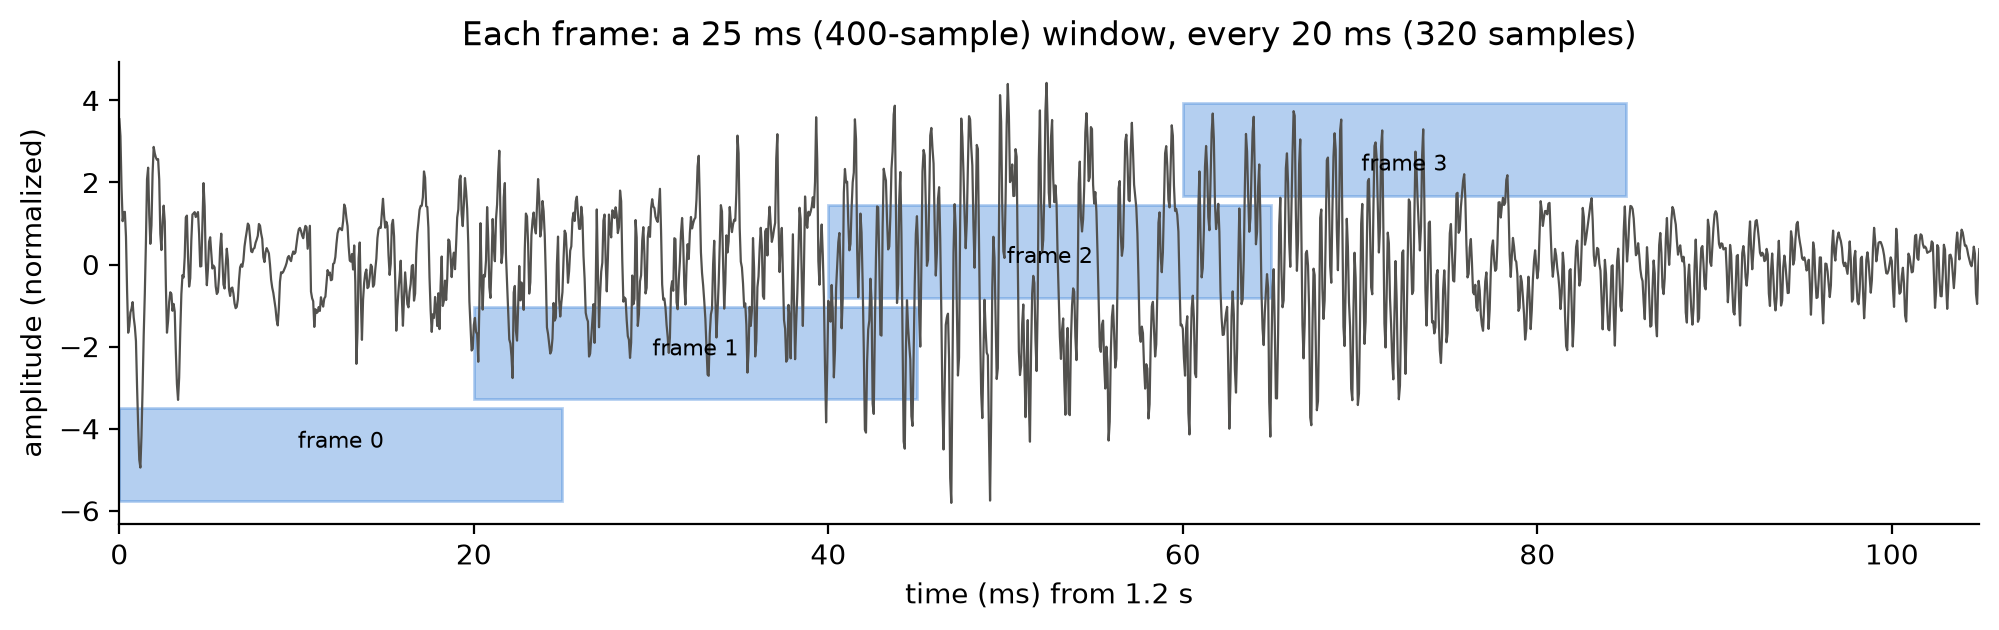

In [12]:
start, n_frames = 1.2, 4  # seconds into the recording, frames to show
t0 = int(start * SAMPLE_RATE)
segment = wave[0, t0:t0 + 320 * n_frames + 400].numpy()
ms = np.arange(len(segment)) / SAMPLE_RATE * 1000

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(ms, segment, lw=0.8, color="#52514e")
for f in range(n_frames):
    left = f * 20
    ax.axvspan(left, left + 25, ymin=0.05 + 0.22 * (f % 4), ymax=0.25 + 0.22 * (f % 4),
               color=COLORS["conv"], alpha=0.35)
    ax.text(left + 12.5, segment.min() + (segment.max() - segment.min()) * (0.15 + 0.22 * (f % 4)) - 0.05,
            f"frame {f}", ha="center", va="center", fontsize=8)
ax.set(xlabel=f"time (ms) from {start} s", ylabel="amplitude (normalized)", xlim=(0, ms[-1]),
       title="Each frame: a 25 ms (400-sample) window, every 20 ms (320 samples)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The output of the feature encoder for the whole recording: 512 channels per frame, plotted like a spectrogram
(each channel scaled to its own maximum). Channels light up at the sound events visible in the waveform, and
different channels respond to different events — the CNN learned its own filterbank.

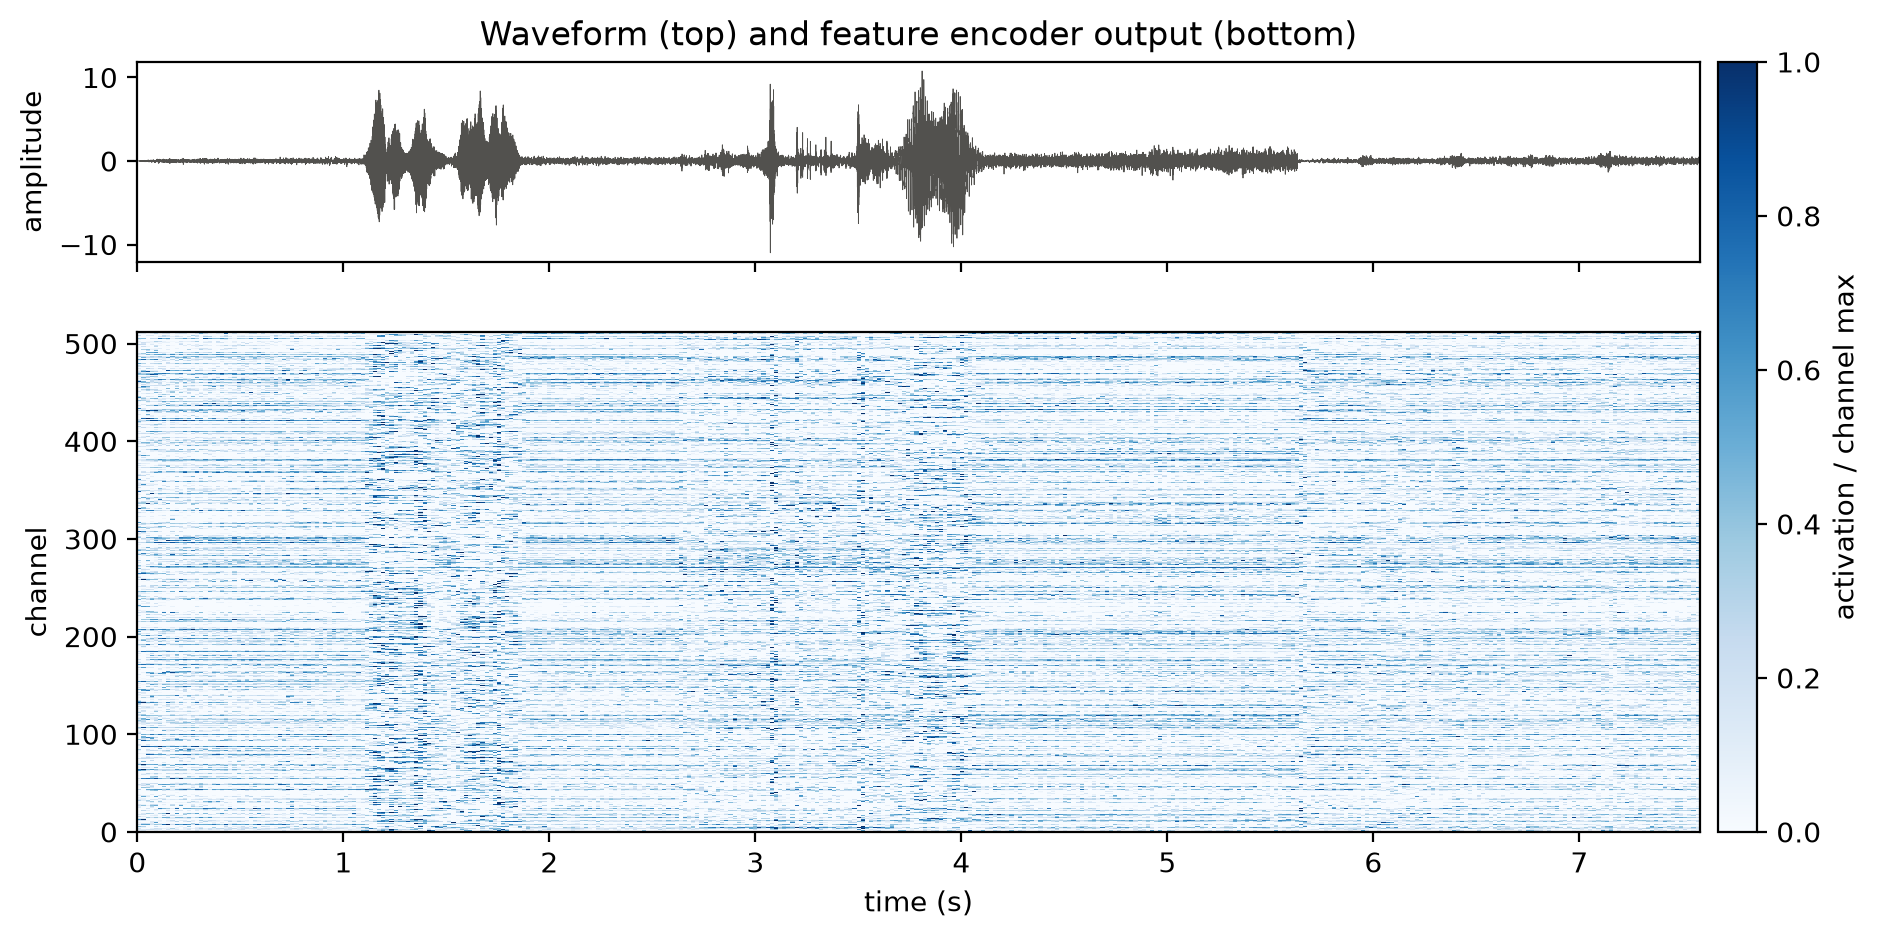

In [13]:
with torch.no_grad():
    features = model.feature_extractor(wave)[0].numpy()  # (512, T)
scaled = np.maximum(features, 0) / np.maximum(features.max(axis=1, keepdims=True), 1e-6)  # GELU outputs can be slightly negative
duration = wave.shape[-1] / SAMPLE_RATE

fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [1, 2.5]})
top.plot(np.arange(wave.shape[-1]) / SAMPLE_RATE, wave[0], lw=0.3, color="#52514e")
top.set(ylabel="amplitude", xlim=(0, duration), title="Waveform (top) and feature encoder output (bottom)")
image = bottom.imshow(scaled, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                      extent=(0, duration, 0, features.shape[0]), interpolation="nearest")
bottom.set(xlabel="time (s)", ylabel="channel")
fig.colorbar(image, ax=[top, bottom], label="activation / channel max", pad=0.01)
plt.show()

## 4. The encoder

### Positional embedding: a convolution instead of sinusoids

Self-attention by itself doesn't know the order of the frames. Instead of the sinusoidal or learned position vectors
of the original Transformer, wav2vec2 adds the output of a wide **grouped convolution** over time to the frames:

- kernel 128 frames (≈ 2.6 s), padding 64 on both sides; because the kernel is even this yields one extra frame,
  which `Wav2Vec2SamePadLayer` removes;
- 16 groups: the 768 channels are split into 16 groups of 48, each convolved only with itself
  (16× fewer weights than a full convolution: $768 \cdot 48 \cdot 128 \approx 4.7$ M);
- **weight normalization**: the kernel is stored as a direction $v$ and a magnitude $g$, $w = g \, v / \lVert v \rVert$,
  with the norm taken for each of the 128 kernel positions.

In [14]:
pos = model.encoder.pos_conv_embed.conv
for name, p in pos.parametrizations.weight.named_parameters():
    print(name, tuple(p.shape))   # original0 = g (per kernel position), original1 = v (direction)
print("bias", tuple(pos.bias.shape))

original0 (1, 1, 128)
original1 (768, 48, 128)
bias (768,)


How strongly the positional convolution weighs each of its 128 frames (the magnitude $g$ for each kernel position).
Although the kernel spans ±1.3 s, the learned weights concentrate on the closest ±0.1 s.

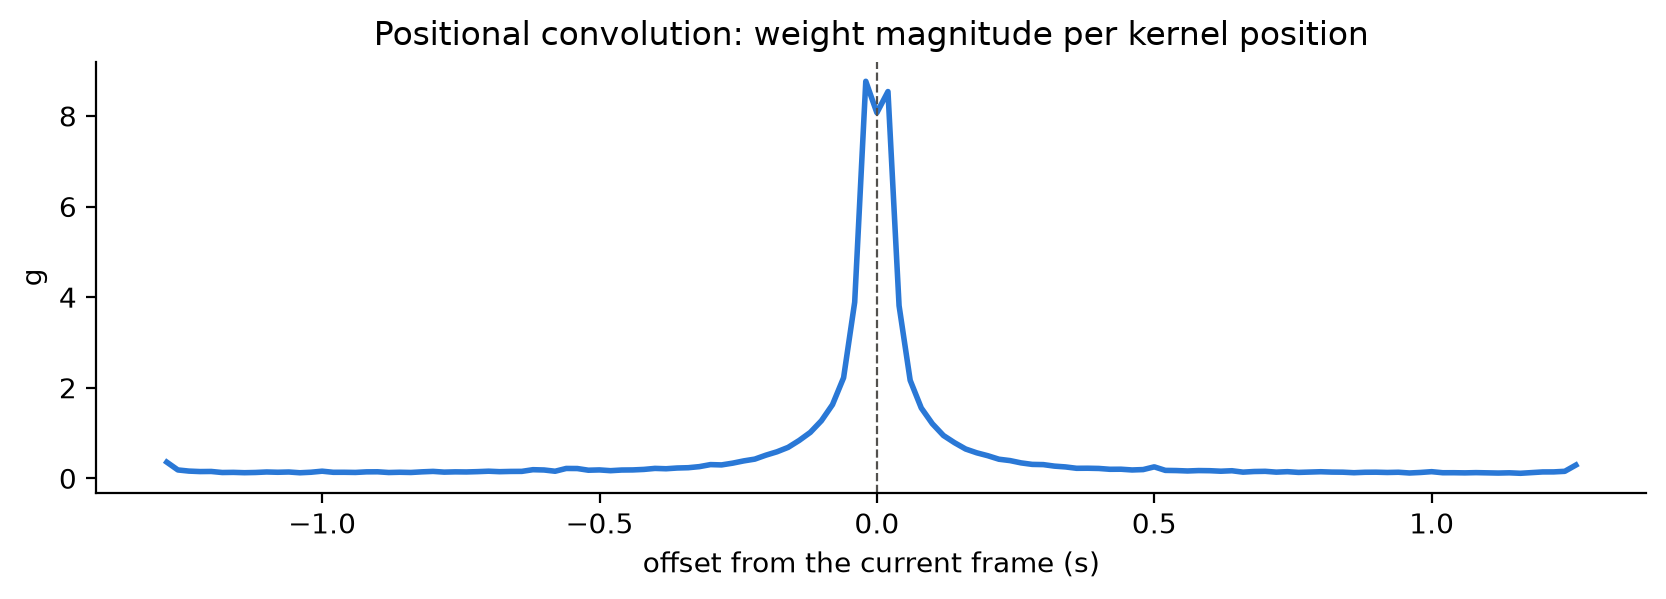

In [15]:
g = pos.parametrizations.weight.original0.detach().flatten()
offsets = np.arange(len(g)) - 64  # kernel position relative to the output frame (in frames of 20 ms)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(offsets * 0.02, g, color=COLORS["conv"], lw=2)
ax.axvline(0, color="#52514e", lw=0.8, ls="--")
ax.set(xlabel="offset from the current frame (s)", ylabel="g", title="Positional convolution: weight magnitude per kernel position")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### The Transformer layers

`facebook/wav2vec2-base` uses the **post-norm** arrangement of the original Transformer (`do_stable_layer_norm=False`;
the larger wav2vec2 models use pre-norm). With $x$ of shape $(T, 768)$:

$$h = \mathrm{LN}_1\big(x + \mathrm{MultiHeadAttention}(x)\big) \qquad\qquad y = \mathrm{LN}_2\big(h + W_2\,\mathrm{GELU}(W_1 h + b_1) + b_2\big)$$

Multi-head attention with $12$ heads of $d = 768 / 12 = 64$ dimensions: for each head $i$,

$$Q_i = x W^Q_i,\quad K_i = x W^K_i,\quad V_i = x W^V_i, \qquad \mathrm{head}_i = \mathrm{softmax}\!\left(\frac{Q_i K_i^\top}{\sqrt{d}}\right) V_i$$

$$\mathrm{MultiHeadAttention}(x) = [\mathrm{head}_1, \dots, \mathrm{head}_{12}]\, W^O$$

In the code, $W^Q_1 \dots W^Q_{12}$ are one `Linear(768, 768)` (`q_proj`) whose output is reshaped into 12 heads.
Every frame attends to every other frame (no causal mask): the encoder sees the whole recording.

`hidden_states` has 13 entries: the input to the first Transformer layer (after the positional embedding and layer
norm) and the outputs of the 12 layers. These are the per-frame features the assignment's heads are trained on.

### What the attention heads do

Row $t$ of an attention map is the softmax distribution over which frames frame $t$ takes information from
(uniform attention over this recording would be $1/T \approx 0.003$ everywhere).
A few heads of an early, a middle, and the last layer:

In [16]:
# Run the model once more, asking for the attention weights of every layer. The default attention
# implementation (PyTorch's fused scaled_dot_product_attention) doesn't return them, so switch to the plain one.
model.set_attn_implementation("eager")
with torch.no_grad():
    out = model(wave, output_hidden_states=True, output_attentions=True)
attention_maps = {i: a[0] for i, a in enumerate(out.attentions)}  # layer -> (heads, T, T)
duration = wave.shape[-1] / SAMPLE_RATE
print(len(out.attentions), "layers, each", tuple(out.attentions[0].shape), "(batch, heads, query frame, attended frame)")

12 layers, each (1, 12, 378, 378) (batch, heads, query frame, attended frame)


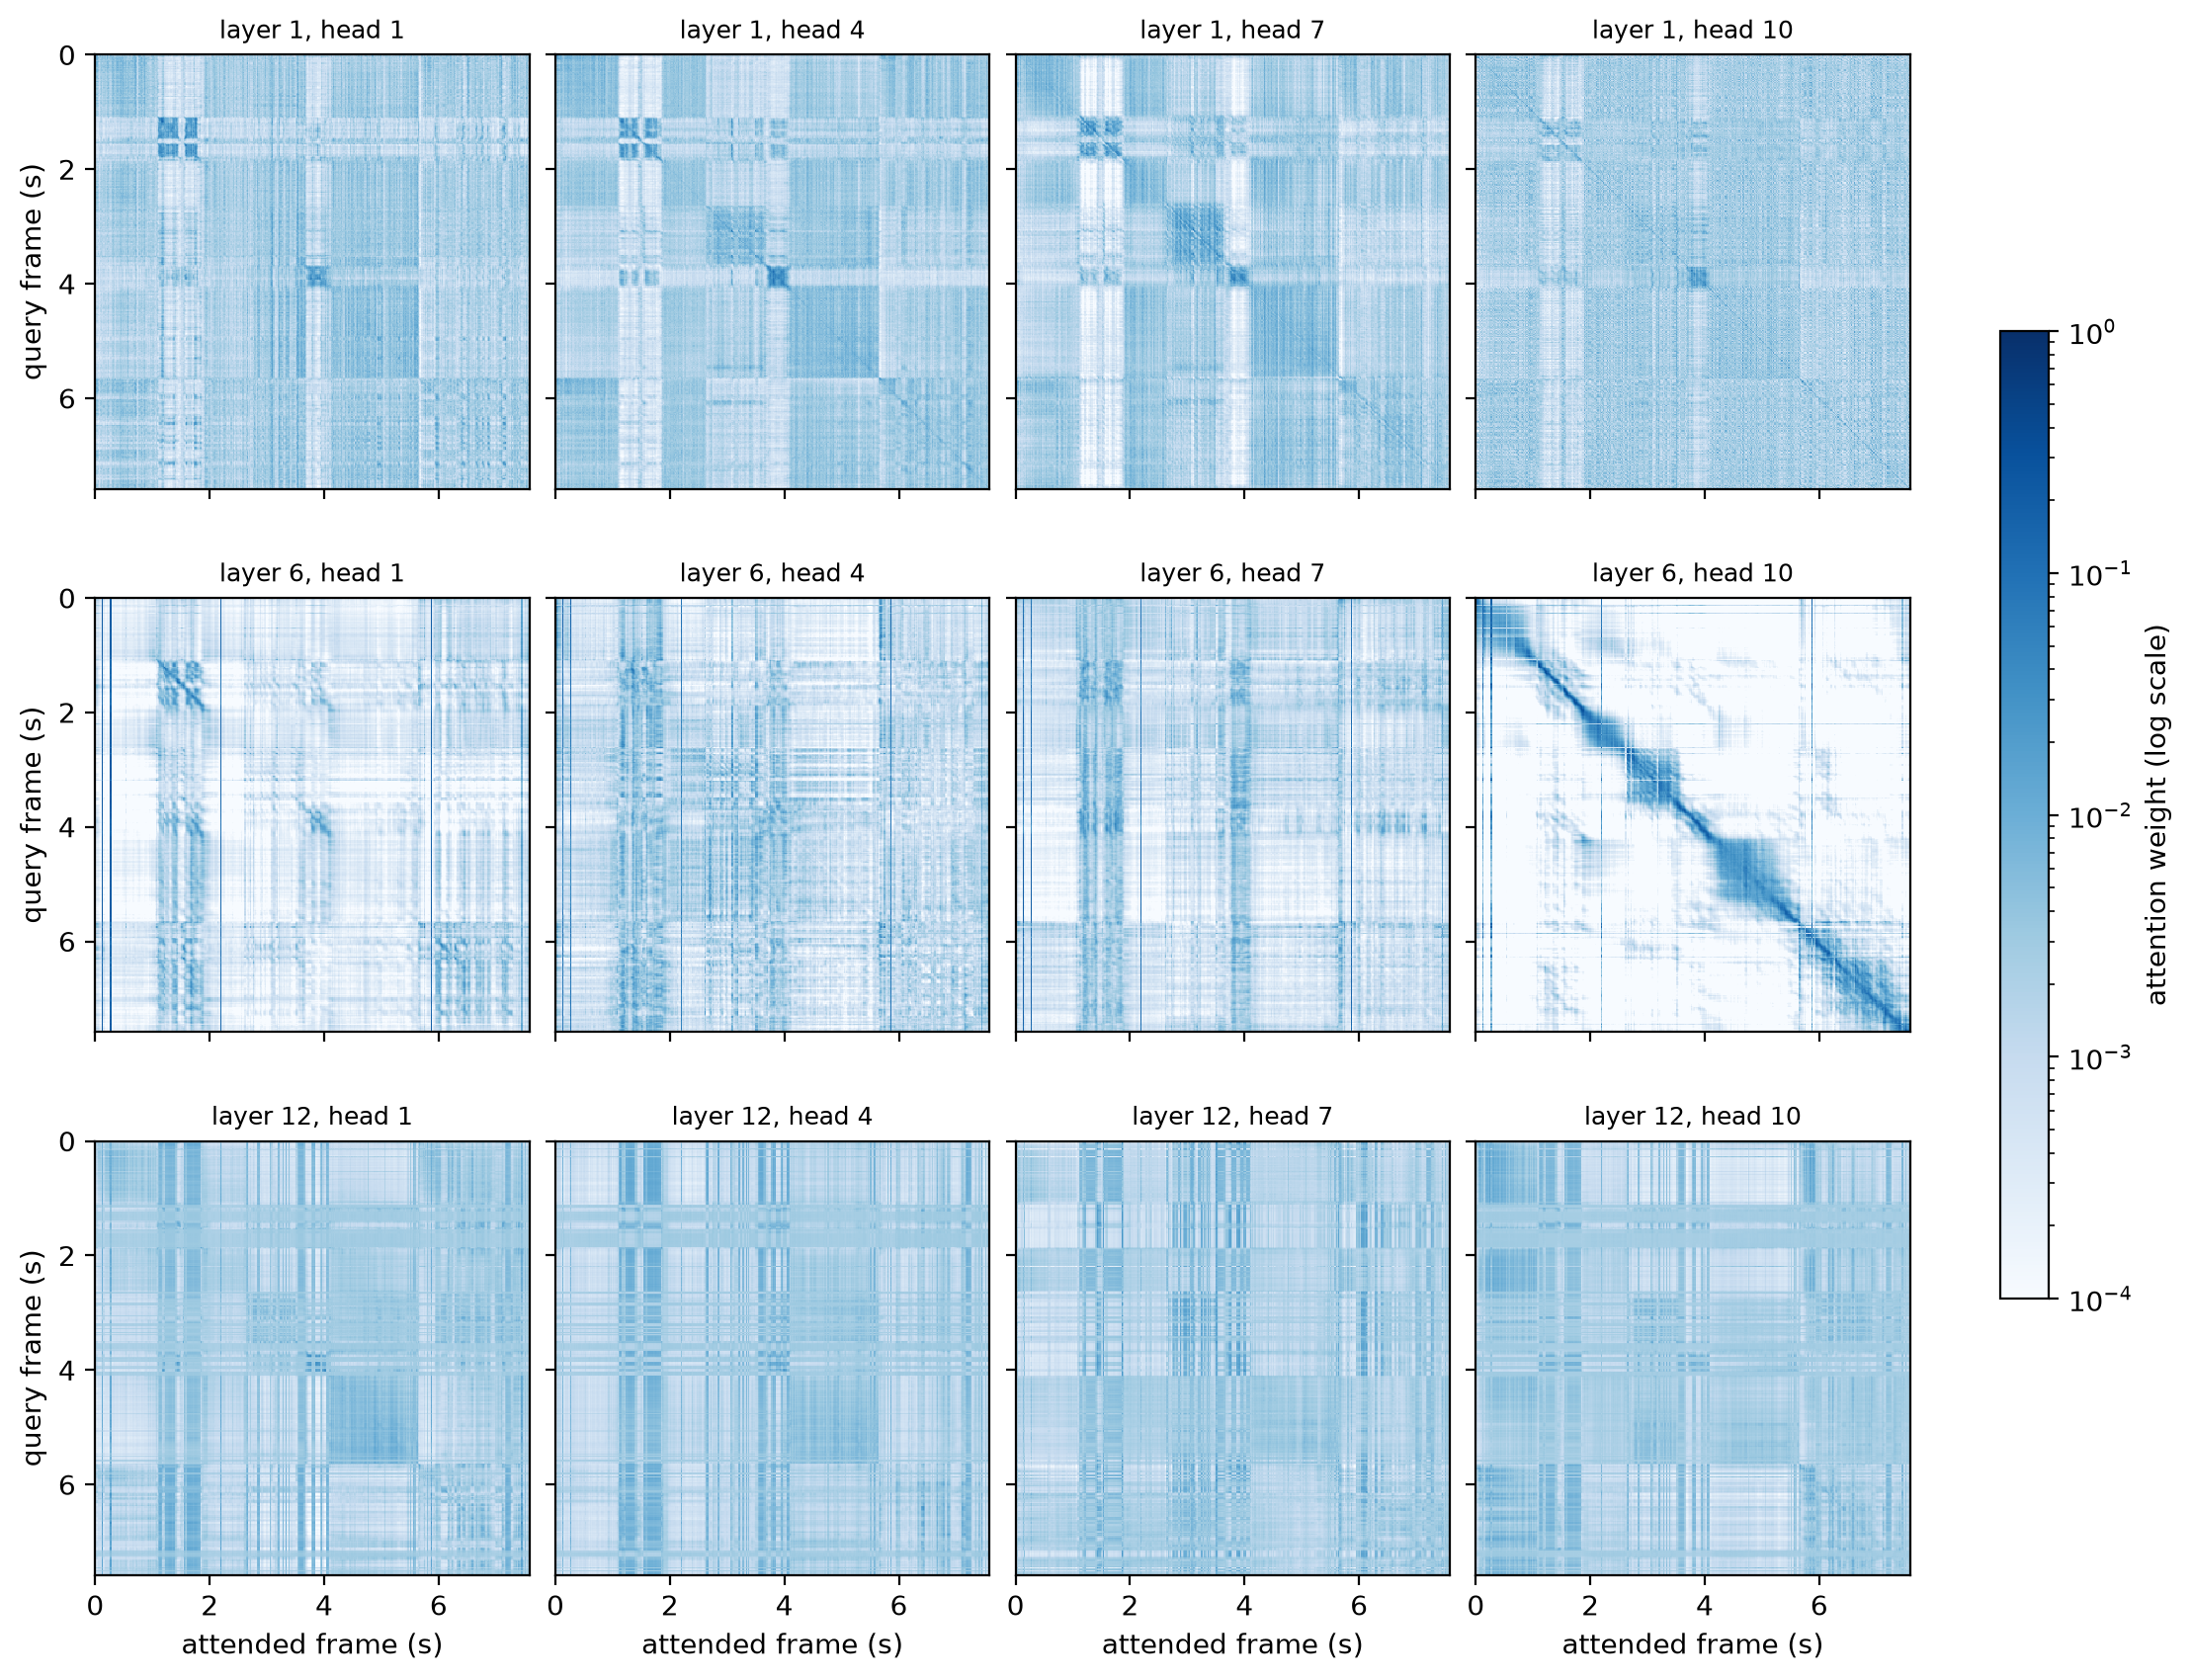

In [17]:
layers, head_ids = [0, 5, 11], [0, 3, 6, 9]
fig, axes = plt.subplots(len(layers), len(head_ids), figsize=(11, 8.5), sharex=True, sharey=True, layout="constrained")
log_scale = matplotlib.colors.LogNorm(vmin=1e-4, vmax=1)
for row, layer_id in zip(axes, layers):
    for ax, head in zip(row, head_ids):
        image = ax.imshow(attention_maps[layer_id][head].numpy(), cmap="Blues", norm=log_scale,
                          extent=(0, duration, duration, 0), interpolation="nearest")
        ax.set_title(f"layer {layer_id + 1}, head {head + 1}", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("attended frame (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("query frame (s)")
fig.colorbar(image, ax=axes, label="attention weight (log scale)", shrink=0.6)
plt.show()

Some heads look at the current frame and its neighbours (a bright diagonal: local, convolution-like), others spread
over the whole recording or focus on particular events (vertical stripes: every frame attends to the same frames).

## 5. Speech recognition: clip in, text out

wav2vec2 was pre-trained without any transcripts. To turn it into a speech recognizer, the authors fine-tuned it on
960 hours of LibriSpeech audiobooks *with* their transcripts: `facebook/wav2vec2-base-960h`. The architecture is
the one dissected above plus **one** dense layer on top, `lm_head`, which maps each frame's 768 numbers to scores for
32 characters.

The test clips are short phrases from the BSD10k collection used in the CLAP notebook (Freesound recordings,
CC0 or CC BY). The expected text comes from each clip's Freesound description.

In [19]:
from IPython.display import Audio
from scipy.io import wavfile
from scipy.signal import resample_poly
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor, pipeline

BSD = "danylo-ucla/bsd/bsd10k"
phrases = {  # Freesound sound id -> what is said, according to the clip's description
    405261: "for hope and dreams",
    209413: "look over there",
    240674: "you have been denied",
    200381: "gravy is a meat extender",
    369908: "audio signal processing for music applications",
}
metadata = pd.read_csv(f"s3://{BSD}/metadata/BSD10k_metadata.csv").set_index("sound_id").loc[list(phrases)]
metadata[["title", "uploader", "license"]]

,title,uploader,license
sound_id,,,
405261,ZierotaHopeDreams2.wav,mousepatrol,http://creativecommons.org/publicdomain/zero/1.0/
209413,"Look, Over There.flac",qubodup,https://creativecommons.org/licenses/by/4.0/
240674,You have been denied,Zajo,http://creativecommons.org/publicdomain/zero/1.0/
200381,gravy is a meat extender.wav,cognito perceptu,http://creativecommons.org/publicdomain/zero/1.0/
369908,male speech,germanio,http://creativecommons.org/publicdomain/zero/1.0/


In [20]:
def load_clip(sound_id):
    # The clips are 44.1 kHz 16-bit WAV files; wav2vec2 needs 16 kHz.
    with fs.open(f"{BSD}/audio/{sound_id}.wav", "rb") as f:
        rate, samples = wavfile.read(f)
    samples = samples.reshape(len(samples), -1).mean(axis=1) / 32768  # stereo -> mono, int16 -> [-1, 1]
    return resample_poly(samples, SAMPLE_RATE, rate).astype(np.float32)


clip = load_clip(405261)
print(f"{len(clip)} samples = {len(clip) / SAMPLE_RATE:.2f} s")
Audio(clip, rate=SAMPLE_RATE)

28793 samples = 1.80 s


### The pipeline

`transformers.pipeline` bundles the preprocessing (normalizing the waveform), the model, and the decoding of its
output into text:

In [21]:
asr = pipeline("automatic-speech-recognition", model="facebook/wav2vec2-base-960h")
asr(clip)

{'text': 'FOR HOPE AND DREAMS'}

### Under the hood

The pipeline holds a `Wav2Vec2ForCTC` model and a `Wav2Vec2Processor`. The model contains the same `Wav2Vec2Model`
as before (`.wav2vec2`), plus the head:

In [22]:
asr_model, processor = asr.model.eval(), Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h")
same_shapes = all(a.shape == b.shape for a, b in zip(asr_model.wav2vec2.parameters(), model.parameters()))
print("same backbone architecture:", same_shapes)
print("extra head:", asr_model.lm_head, f"({n_params(asr_model.lm_head)} parameters)")
print("dropout before the head:", asr_model.dropout)

same backbone architecture: True
extra head: Linear(in_features=768, out_features=32, bias=True) (24608 parameters)
dropout before the head: Dropout(p=0.1, inplace=False)


The 32 outputs are a character vocabulary: letters, the apostrophe, `|` between words, and special tokens.

In [23]:
vocabulary = processor.tokenizer.convert_ids_to_tokens(list(range(asr_model.config.vocab_size)))
print(vocabulary)

['<pad>', '<s>', '</s>', '<unk>', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z']


In [24]:
inputs = processor(clip, sampling_rate=SAMPLE_RATE, return_tensors="pt")  # zero mean, unit variance
with torch.no_grad():
    logits = asr_model(inputs.input_values).logits                     # (batch, frames, 32)
probabilities = logits.softmax(dim=-1)[0]
best = logits.argmax(dim=-1)[0]
print("logits:", tuple(logits.shape))
print("best character per frame:")
print("".join(vocabulary[k].replace("<pad>", "_") for k in best))

logits: (1, 89, 32)
best character per frame:
_____F___OR__||__H_____O_P_E__|__________________AN_D||_D_RR__EEAA_MM_____SS_||__________


### CTC decoding

The model was trained with **CTC** (Connectionist Temporal Classification, Graves et al. 2006). The model outputs one
character for every 20 ms frame, but speech has far fewer characters than frames, and nobody marked which frame each
character belongs to. CTC solves this with an extra *blank* token (here `<pad>`, printed as `_`): the frame-level
output is turned into text by

1. merging repeated characters (`hhh` → `h`),
2. then removing the blanks (a blank between two equal characters keeps them apart: `l_l` → `ll`),
3. and replacing the word separator `|` by a space.

During training, the CTC loss sums the probability of *all* frame-level sequences that collapse to the true
transcript, so no alignment is needed.

In [25]:
def ctc_greedy_decode(ids):
    merged = [k for t, k in enumerate(ids) if t == 0 or k != ids[t - 1]]   # 1. merge repeats
    kept = [vocabulary[k] for k in merged if k != processor.tokenizer.pad_token_id]  # 2. drop blanks
    return "".join(kept).replace("|", " ").strip()                          # 3. word separators


text = ctc_greedy_decode(best.tolist())
print(repr(text))
assert text == processor.decode(best)  # the processor does the same

'FOR HOPE AND DREAMS'


The frame-level probabilities, below the waveform. Most frames are confidently blank; each character "fires" in one
or two frames, roughly where it is spoken.

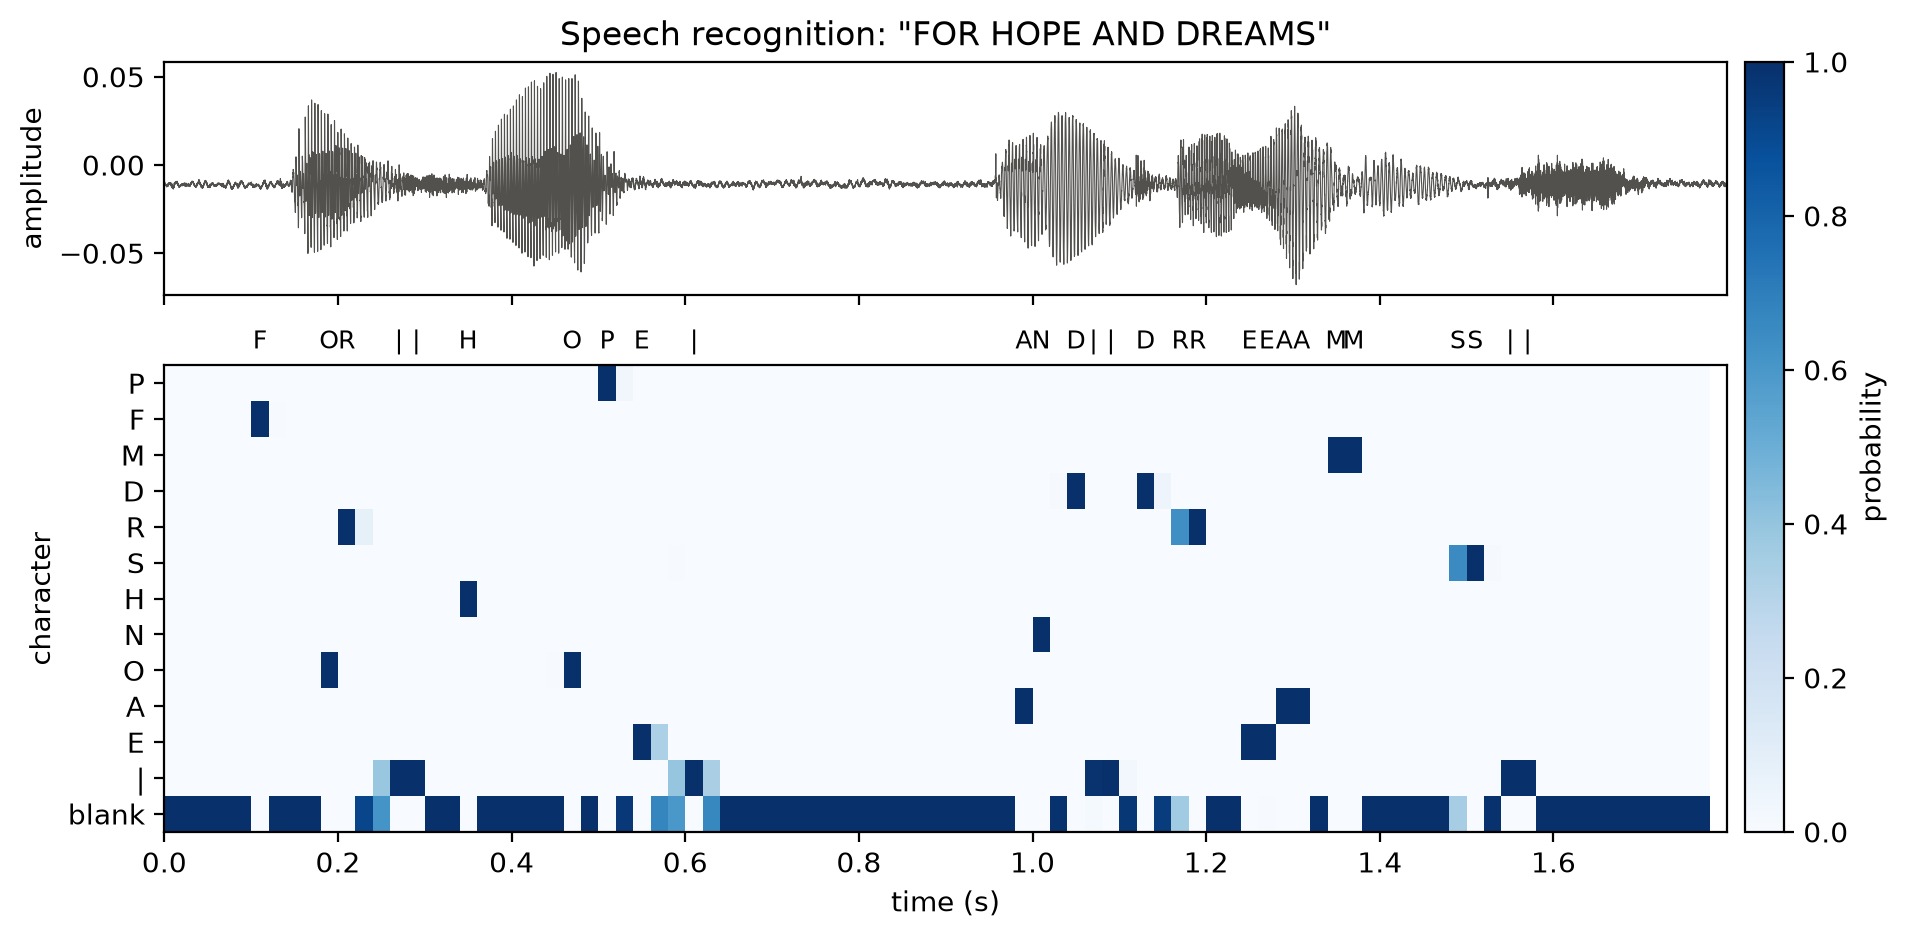

In [26]:
shown = sorted(set(best.tolist()))  # only the characters that win at least one frame
frames = np.arange(len(best)) * 0.02 + 0.01  # frame centers (s)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
top.plot(np.arange(len(clip)) / SAMPLE_RATE, clip, lw=0.4, color="#52514e")
top.set(ylabel="amplitude", xlim=(0, len(clip) / SAMPLE_RATE), title=f"Speech recognition: \"{text}\"")
image = bottom.imshow(probabilities[:, shown].T.numpy(), aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                      extent=(0, len(best) * 0.02, -0.5, len(shown) - 0.5), interpolation="nearest")
bottom.set_yticks(range(len(shown)), [vocabulary[k].replace("<pad>", "blank") for k in shown])
bottom.set(xlabel="time (s)", ylabel="character")
for t, k in zip(frames, best.tolist()):
    if k != processor.tokenizer.pad_token_id:
        bottom.text(t, len(shown) - 0.2, vocabulary[k], ha="center", va="bottom", fontsize=9, clip_on=False)
fig.colorbar(image, ax=[top, bottom], label="probability", pad=0.01)
plt.show()

### More clips

In [27]:
results = pd.DataFrame({
    "expected": phrases,
    "recognized": {sound_id: asr(load_clip(sound_id))["text"].lower() for sound_id in phrases},
})
results

,expected,recognized
405261,for hope and dreams,for hope and dreams
209413,look over there,look over there
240674,you have been denied,you have been denied i
200381,gravy is a meat extender,grivy is a made extender
369908,audio signal processing for music applications,ordiou seen laprecitin for music application


The mistakes sound right: "grivy" for *gravy*, "made extender" for *meat extender*, "ordiou seen laprecitin" for
*audio signal processing*. The model picks each character from what it hears, with no knowledge of which words
exist or which sentences make sense, and it only heard read audiobooks during fine-tuning — not voice actors
in home studios. Speech recognizers improve on this by adding a language model to the decoding, or by being
trained on much more varied audio (e.g. Whisper, which predicts text with a Transformer decoder).